# Credit Card Fraud Detection — Exploratory Data Analysis

**Dataset:** ULB Machine Learning Group — anonymised European cardholder transactions, September 2013 (2 days).

**Goal of this notebook:** understand the data well enough to make defensible modelling decisions — above all, how severe the class imbalance is and which features actually separate fraud from legitimate activity.

**Note on the features:** `V1`–`V28` are principal components, so they are already scaled, mutually uncorrelated, and have no interpretable meaning. Only `Time` and `Amount` are in their original units.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

df = pd.read_csv('data/creditcard.csv')
print(df.shape)
df.head()

ImportError: DLL load failed while importing base: An Application Control policy has blocked this file.

## 1. Data integrity check

Confirm what the data card claims rather than assuming it: no missing values, correct dtypes, and check for duplicate rows (the data card does not mention these, but they exist).

In [ ]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('\nDtypes:')
print(df.dtypes.value_counts())

Missing values: 0
Duplicate rows: 1081

Dtypes:
float64    30
int64       1
Name: count, dtype: int64


In [ ]:
dupes = df[df.duplicated(keep=False)]
print('Total rows involved in duplication:', len(dupes))
print(dupes['Class'].value_counts())

Total rows involved in duplication: 1854
Class
0    1822
1      32
Name: count, dtype: int64


In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['Class'].value_counts())


(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


**Decision to record:** if duplicates exist, decide whether to drop them *before* splitting. Identical rows appearing in both train and test would leak information and inflate measured performance.

## 2. Class imbalance

This single number drives every later decision: metric choice, resampling strategy, and the decision threshold.

In [ ]:
counts = df['Class'].value_counts()
pct = df['Class'].value_counts(normalize=True) * 100

print(counts)
print()
print(pct.round(4))
print(f'\nImbalance ratio: 1 fraud per {counts[0] / counts[1]:.0f} legitimate transactions')

Class
0    283253
1       473
Name: count, dtype: int64

Class
0    99.8333
1     0.1667
Name: proportion, dtype: float64

Imbalance ratio: 1 fraud per 599 legitimate transactions


**Why accuracy is useless here:** a model that predicts "not fraud" for every single transaction scores ~99.83% accuracy while catching zero fraud. Primary metric for this project: **area under the precision-recall curve (AUPRC)**, with precision and recall reported at the chosen operating threshold.

## 3. Transaction amount

One of only two interpretable features. Does fraud concentrate at particular amounts?

In [ ]:
print(df.groupby('Class')['Amount'].describe().round(2))

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


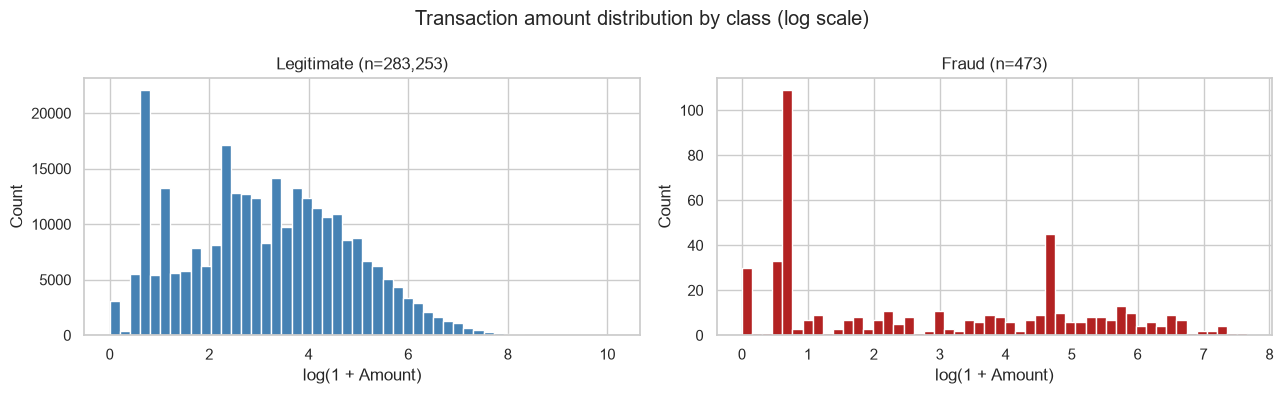

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for cls, ax, label in zip([0, 1], axes, ['Legitimate', 'Fraud']):
    subset = df.loc[df['Class'] == cls, 'Amount']
    ax.hist(np.log1p(subset), bins=50, color='steelblue' if cls == 0 else 'firebrick')
    ax.set_title(f'{label} (n={len(subset):,})')
    ax.set_xlabel('log(1 + Amount)')
    ax.set_ylabel('Count')

plt.suptitle('Transaction amount distribution by class (log scale)')
plt.tight_layout()
plt.show()

Log scale is used because `Amount` is heavily right-skewed — a raw histogram would compress almost everything into the first bin.

**Write your observation here:** does fraud skew towards small amounts, large amounts, or neither?

## 4. Time

`Time` is seconds elapsed since the first transaction, spanning roughly two days. Converting to hour-of-day makes it interpretable.

**Caveat to state explicitly:** two days is a very short window. Any daily pattern found here is suggestive, not evidence of a stable cycle.

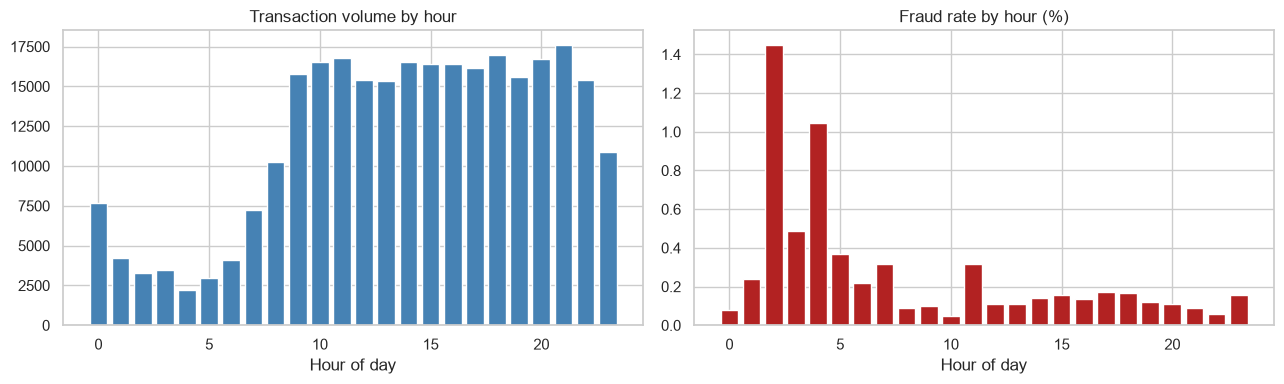

,sum,count,fraud_rate_pct
Hour,,,
0.0,6,7647,0.078
1.0,10,4208,0.238
2.0,48,3308,1.451
3.0,17,3487,0.488
4.0,23,2204,1.044
5.0,11,2988,0.368
6.0,9,4082,0.220
7.0,23,7233,0.318
8.0,9,10232,0.088


In [ ]:
df['Hour'] = (df['Time'] // 3600) % 24

hourly = df.groupby('Hour')['Class'].agg(['sum', 'count'])
hourly['fraud_rate_pct'] = hourly['sum'] / hourly['count'] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(hourly.index, hourly['count'], color='steelblue')
axes[0].set_title('Transaction volume by hour')
axes[0].set_xlabel('Hour of day')

axes[1].bar(hourly.index, hourly['fraud_rate_pct'], color='firebrick')
axes[1].set_title('Fraud rate by hour (%)')
axes[1].set_xlabel('Hour of day')

plt.tight_layout()
plt.show()

hourly.round(3)

**Write your observation here:** fraud rate tends to rise in low-volume hours. Note the raw fraud counts too — a high percentage built on very few transactions is not a reliable signal.

## 5. Which PCA components separate the classes?

A full correlation heatmap is near-useless here: PCA guarantees the components are uncorrelated with each other. The useful question is which components differ *between classes*.

Using the standardised mean difference (Cohen's d) rather than correlation with the label.

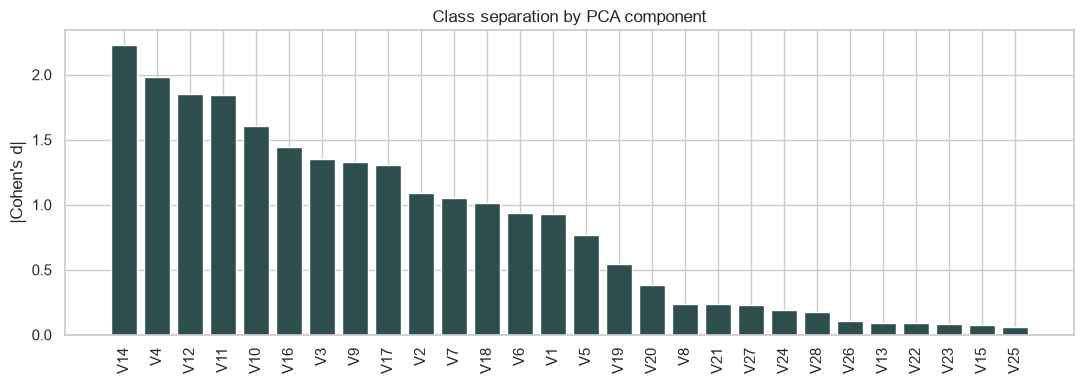

Top 8 most separating components:
V14    2.228
V4     1.985
V12    1.848
V11    1.844
V10    1.603
V16    1.445
V3     1.350
V9     1.325
dtype: float64


In [ ]:
v_cols = [c for c in df.columns if c.startswith('V')]

fraud = df[df['Class'] == 1]
legit = df[df['Class'] == 0]

pooled_sd = np.sqrt((fraud[v_cols].var() + legit[v_cols].var()) / 2)
cohens_d = ((fraud[v_cols].mean() - legit[v_cols].mean()) / pooled_sd)

ranked = cohens_d.abs().sort_values(ascending=False)

plt.figure(figsize=(11, 4))
plt.bar(ranked.index, ranked.values, color='darkslategray')
plt.xticks(rotation=90)
plt.ylabel("|Cohen's d|")
plt.title('Class separation by PCA component')
plt.tight_layout()
plt.show()

print('Top 8 most separating components:')
print(ranked.head(8).round(3))

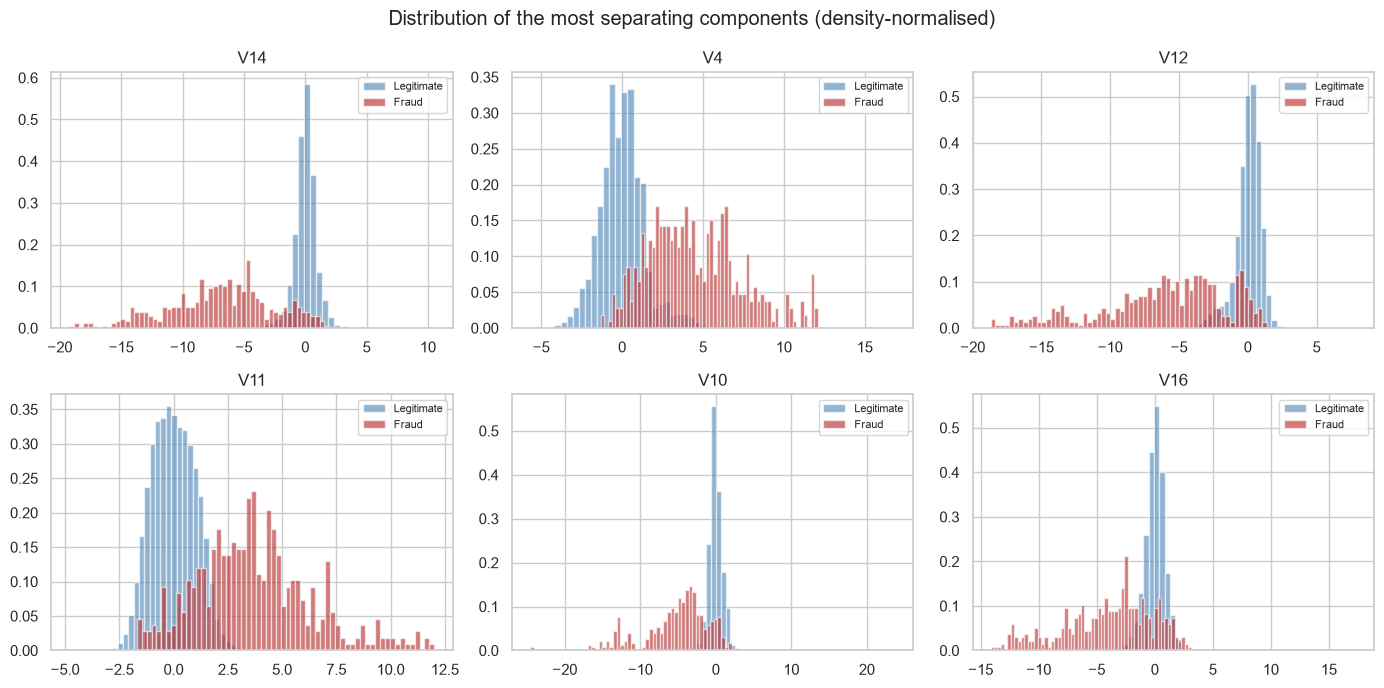

In [ ]:
top_features = ranked.head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for feat, ax in zip(top_features, axes.ravel()):
    ax.hist(legit[feat], bins=60, density=True, alpha=0.6, label='Legitimate', color='steelblue')
    ax.hist(fraud[feat], bins=60, density=True, alpha=0.6, label='Fraud', color='firebrick')
    ax.set_title(feat)
    ax.legend(fontsize=8)

plt.suptitle('Distribution of the most separating components (density-normalised)')
plt.tight_layout()
plt.show()

`density=True` is essential — without it the 492 fraud cases would be invisible next to 284,315 legitimate ones.

## 6. Findings

Fill this in once the cells above have run. Keep it to decisions, not description:

1. **Imbalance:** ___ — therefore AUPRC as the primary metric, stratified splitting throughout.
2. **Duplicates:** ___ — therefore drop / keep, before splitting.
3. **Amount:** ___ — therefore scale with RobustScaler (robust to the extreme right tail).
4. **Time:** ___ — therefore keep `Hour` / drop it.
5. **Separating components:** ___ — useful as a sanity check on model feature importances later.

**Next notebook:** `02_modelling.ipynb` — stratified split, baseline logistic regression with `class_weight='balanced'`, then gradient boosting, compared on AUPRC. Threshold selection is treated as a separate, explicitly cost-based decision.